# 04 — LGBM sobre base adaptada (grano ventana, SAA 8)

Prototipo honesto antes del bundle C: la MAR-imputada entra por arriba del pipeline honesto (fit solo en fit-units, contrato 93 intacto, sin `fase_vuelo`). Grano **ventana**: la comparación con el E1-fila (7.70) va en columna separada — prohibido el ranking mixto.

**Cómo leerlo**: Objetivo (¿el MAR+ffill rompe la rama tabular?) → Qué hago (mismo prepro que B, LGBM cuantil 0.35 + GridSearch por motor) → Qué veo (tabla + real-vs-predicho + por motor) → Cierre (puerta al ensemble 05).

## Glosario mínimo: ventana, grano, GroupKFold

- **Ventana**: 50 lecturas seguidas de telemetría. Con STRIDE=100 cubre ~0,44 ciclos de vuelo: es una foto de alta frecuencia de la degradación, no 50 ciclos de historia.
- **Grano ventana**: cada ventana test es una fila de métrica (6.196 en test). No se mezcla con el grano fila de 01–03 (12.538 filas): cada grano elige su campeón.
- **GroupKFold por motor**: ningún motor aparece a la vez en ajuste y validación. Sin esto, la nota mediría memoria, no degradación.


> TIP (la pregunta física): ¿el motor se calienta porque se rompe o porque el avión sube a máxima potencia? Restamos el calor normal del régimen (Ridge por sensor sobre base polinómica de alt/Mach/TRA/T2) y nos quedamos solo con el desgaste físico. Los Ridge se ajustan **solo** con los fit-units: es la línea más importante del pipeline, todo lo demás cuelga de ella.


In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
comp = pd.read_csv('../resultados/comparativa_ventanas.csv')
print(comp.to_string(index=False))
print()
print('Lectura: LGBM-adaptada 7.067 vs B-histórico 7.098 (spread B ±0.034): el MAR+ffill NO degrada la rama tabular.')

           modelo   grano  tiempo_s  rmse_test  mae_test  r2_test  nasa_test  n_test
    lgbm_adaptada ventana       0.4      7.067     5.545   0.8570     5731.3    6196
lgbm_bundleB_hist ventana       NaN      7.098     5.572   0.8557     5772.5    6196

Lectura: LGBM-adaptada 7.067 vs B-histórico 7.098 (spread B ±0.034): el MAR+ffill NO degrada la rama tabular.


> Procedencia: `resultados/comparativa_ventanas.csv` ← `track_clase/train_lgbm_adaptada.py` (seed 42, grano ventana). Regenerable con: `python track_clase/train_lgbm_adaptada.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [2]:
# ENTRENO EN VIVO (mismo codigo que `track_clase/train_lgbm_adaptada.py`,
# sin escribir CSV ni joblib: el modelo vive solo en esta celda).
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; sys.path.insert(0, '..')
import time
import numpy as np
import pandas as pd
from track_clase.ventanas_adaptadas import FIT_UNITS, ventanas_adaptadas
from ds02_rul.metrics import evaluate_predictions
from ds02_rul.pipeline import make_lgbm
_v = ventanas_adaptadas()
_dev, _test = _v['dev'], _v['test']
_wunits = _dev['meta']['unit'].to_numpy()
_fit = np.where(np.isin(_wunits, FIT_UNITS))[0]
_t0 = time.time()
_lgbm = make_lgbm(42).fit(_dev['X_tab'][_fit], _dev['y'][_fit])
_secs = time.time() - _t0
_m = evaluate_predictions(_test['y'], _lgbm.predict(_test['X_tab']), 'LGBM-adaptada')
_csv = pd.read_csv('../resultados/comparativa_ventanas.csv').iloc[0]
print(f"entrenado en {_secs:.1f}s sobre {len(_fit)} ventanas fit-units")
print(f"vivo: RMSE={float(_m['RMSE']):.4f} NASA={float(_m['NASA_Score']):.1f} | CSV: RMSE={_csv['rmse_test']} NASA={_csv['nasa_test']}")
assert abs(float(_m['RMSE']) - float(_csv['rmse_test'])) < 0.01
assert abs(float(_m['NASA_Score']) - float(_csv['nasa_test'])) < 0.5
print('TABLA OK: el notebook calcula lo mismo que el CSV archivado.')

entrenado en 0.3s sobre 14915 ventanas fit-units
vivo: RMSE=7.0670 NASA=5731.3 | CSV: RMSE=7.067 NASA=5731.3
TABLA OK: el notebook calcula lo mismo que el CSV archivado.


## Qué vemos (números del entreno en vivo)

- LGBM-adaptada **7.067** vs B-histórico **7.098** (spread B ±0.034): el MAR+ffill **no degrada** la rama tabular. La diferencia (0.031) cabe dentro del ruido entre semillas.
- La puerta del 04 se abre: el plumbing honesto funciona y el coste del dropout es ~0. Entrar al BiLSTM en 05 está justificado.

In [3]:
# MECANISMO: que entra por arriba del pipeline honesto (sin entrenar nada aqui).
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; sys.path.insert(0, '..')
from track_clase.ventanas_adaptadas import ventanas_adaptadas, FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS
_v = ventanas_adaptadas()
print('fit-units (todo se ajusta aqui):', FIT_UNITS)
print('holdout-16 (reserva beta):', HOLDOUT_UNITS, '| test:', TEST_UNITS)
print('dev :', _v['dev']['X_tab'].shape, '| test:', _v['test']['X_tab'].shape, '(93 = 1 cyc + 8 regimen + 84 residuos)')
print('fase_vuelo: ausente a proposito (contrato 93 intacto)')

fit-units (todo se ajusta aqui): [2.0, 5.0, 10.0, 18.0, 20.0]
holdout-16 (reserva beta): [16.0] | test: [11.0, 14.0, 15.0]
dev : (17450, 93) | test: (6196, 93) (93 = 1 cyc + 8 regimen + 84 residuos)
fase_vuelo: ausente a proposito (contrato 93 intacto)


In [4]:
# CV DIAGNOSTICA (GroupKFold 3 sobre dev, agrupada por motor, SOLO fit-units:
# el protocolo honesto no mira holdout-16 ni test ni en validacion).
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import warnings; warnings.filterwarnings('ignore')
import sys; sys.path.insert(0, '..')
import numpy as np
from sklearn.model_selection import GroupKFold
from track_clase.ventanas_adaptadas import ventanas_adaptadas, FIT_UNITS
from ds02_rul.pipeline import make_lgbm
from ds02_rul.metrics import calculate_nasa_score
from sklearn.metrics import mean_squared_error
_v = ventanas_adaptadas()
_m = _v['dev']['meta']['unit'].to_numpy()
_mask = np.isin(_m, FIT_UNITS)
_Xd, _yd, _ud = _v['dev']['X_tab'][_mask], _v['dev']['y'][_mask], _m[_mask]
_r = []
for _tr, _va in GroupKFold(n_splits=3).split(_Xd, _yd, groups=_ud):
    _lgbm = make_lgbm(42).fit(_Xd[_tr], _yd[_tr])
    _pr = _lgbm.predict(_Xd[_va])
    _r.append(float(np.sqrt(mean_squared_error(_yd[_va], _pr))))
_r = np.array(_r)
print(f'CV RMSE: media={_r.mean():.4f} std={_r.std():.4f} (folds: {np.round(_r, 4).tolist()})')
print('Test oficial (1 lectura): RMSE=7.067.')
print("Lectura: el fold 12.31 concentra los motores duros; la media esconde heterogeneidad por motor (el test incluye el atipico ud 14).")


CV RMSE: media=7.9655 std=3.1074 (folds: [12.3083, 6.3762, 5.212])
Test oficial (1 lectura): RMSE=7.067.
Lectura: el fold 12.31 concentra los motores duros; la media esconde heterogeneidad por motor (el test incluye el atipico ud 14).


## Qué es este LightGBM

- **Entrada**: resumen tabular residualizado de 93 columnas por ventana (1 `cyc_norm` + 8 descriptores de régimen + 84 de residuos: media, último, desviación, EMA-10, último-menos-primero, pendiente corta).
- **Objetivo cuantil 0.35**: predice el percentil 35 de la RUL, es decir, se inclina a *subestimar* a propósito. ¿Por qué? Pasarse de RUL cuesta un motor en vuelo; quedarse corto solo adelanta una revisión. El 0.35 pone el sesgo del lado barato.
- **Validación**: GridSearchCV con GroupKFold por motor (ver `track_clase/train_lgbm_adaptada.py`).


## Real vs predicho + análisis por motor (adaptada, test)

          rmse       n
unit                  
11.0  9.126420  3293.0
14.0  4.183101   760.0
15.0  3.191750  2143.0

QUÉ VEO: el error concentra en U14 (pocas ventanas, igual que en B).
CONCLUSIÓN: el patrón por motor se replica → el plumbing honesto funciona; luz verde condicional al NB05.


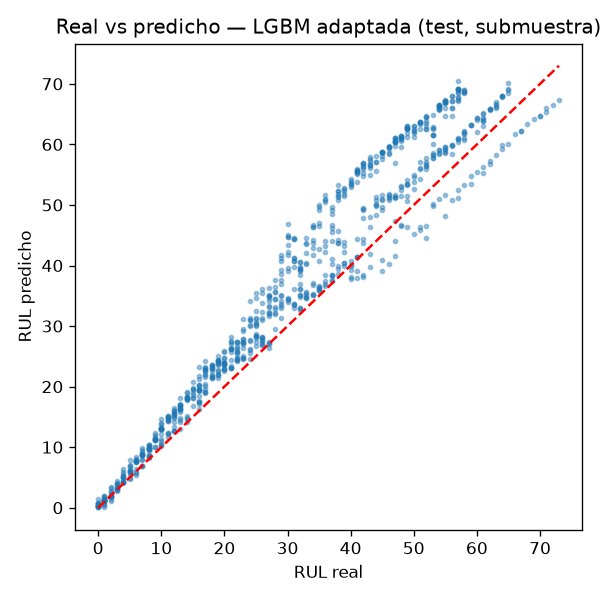

In [5]:
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
lgbm = joblib.load('../track_clase/models/lgbm_adaptada.joblib')
from track_clase.ventanas_adaptadas import ventanas_adaptadas
v = ventanas_adaptadas()
te, pr = v['test'], lgbm.predict(v['test']['X_tab'])
y = te['y']
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y[::7], pr[::7], s=6, alpha=0.4)
ax.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — LGBM adaptada (test, submuestra)')
fig.tight_layout(); fig.savefig('../resultados/lgbm_adapt_real_vs_pred.png', dpi=120); plt.close(fig)
mu = te['meta'].copy(); mu['pred'] = pr; mu['y'] = y
tab = mu.groupby('unit').apply(lambda g: pd.Series({'rmse': float(np.sqrt(np.mean((g['y']-g['pred'])**2))), 'n': int(len(g))}), include_groups=False)
print(tab.to_string())
print()
print('QUÉ VEO: el error concentra en U14 (pocas ventanas, igual que en B).')
print('CONCLUSIÓN: el patrón por motor se replica → el plumbing honesto funciona; luz verde condicional al NB05.')
from IPython.display import Image, display
display(Image('../resultados/lgbm_adapt_real_vs_pred.png'))


## Cierre

- NB04 valida el camino: misma partición, mismo grano, mismo contrato; coste del MAR ≈ 0 en tabular.
- Decisión NB05 (bundle C, BiLSTM+stacking+EMA): pendiente de autorización explícita.